In [1]:
import pandas as pd
import numpy as np

# 11월 12일부터 17일까지 CSV 불러오기
data_list = []

for day in range(12, 18):
    filename = f"VW_SC_TRF_VOL_5M_202611{day:02d}.csv"
    df_day = pd.read_csv(filename)
    data_list.append(df_day)

# 6일치 데이터 합치기
df = pd.concat(data_list, ignore_index=True)

print("전체 데이터 개수:", len(df))
display(df.head())

전체 데이터 개수: 22458


,CROSS_ID,CROSS_NM,DIR_CD,DIR_NM,STND_DT,STND_TM,LTURN_VOL,RTURN_VOL,STURN_VOL,UTURN_VOL,LTURN_VPH,RTURN_VPH,STURN_VPH,UTURN_VPH
0,1385,화랑대역,1,동,20261112,0,2,0,45,0,23,0,538,0
1,1385,화랑대역,2,서,20261112,0,0,19,65,0,0,227,777,0
2,1385,화랑대역,8,남동,20261112,0,5,0,0,0,59,10,0,0
3,457,태릉가스충전소,1,동,20261112,0,0,2,38,0,0,40,764,0
4,457,태릉가스충전소,2,서,20261112,0,1,0,16,0,20,0,321,0


In [2]:
# 공릉역 교차로 ID = 1172
gongneung_df = df[df["CROSS_ID"] == 1172].copy()

# 필요한 컬럼만 선택
gongneung_df = gongneung_df[
    ["STND_DT", "STND_TM", "DIR_NM", "STURN_VOL"]
].copy()

# 인덱스 초기화
gongneung_df = gongneung_df.reset_index(drop=True)

display(gongneung_df.head(10))

,STND_DT,STND_TM,DIR_NM,STURN_VOL
0,20261112,0,동,4
1,20261112,0,서,8
2,20261112,0,남,72
3,20261112,0,북,34
4,20261112,5,동,2
5,20261112,5,서,3
6,20261112,5,남,48
7,20261112,5,북,19
8,20261112,10,동,5
9,20261112,10,서,4


In [3]:
# 날짜별 데이터 개수 확인
print(gongneung_df.groupby("STND_DT").size())

# 방향별 데이터 개수 확인
print(gongneung_df.groupby("DIR_NM").size())

STND_DT
20261112    1152
20261113    1152
20261114    1152
20261115    1152
20261116    1152
20261117    1152
dtype: int64
DIR_NM
남    1728
동    1728
북    1728
서    1728
dtype: int64


In [4]:
# 네 방향의 대기 차량 수 초기화 (네 방향의 대기 차량 수를 저장할 변수)
waiting_cars = {
    "동": 0,
    "서": 0,
    "남": 0,
    "북": 0
}

print(waiting_cars)

{'동': 0, '서': 0, '남': 0, '북': 0}


In [5]:
def distribute_cars(car_count, rng=None):
    if rng is None:
        rng = np.random.default_rng(42)

    # 300초 중 각 초에 차량이 들어올 확률
    probabilities = np.full(300, 1 / 300)

    # 전체 차량 수를 300초에 무작위로 분배
    arrivals = rng.multinomial(
        int(car_count),
        probabilities
    )

    return arrivals

In [6]:
def calculate_reward(waiting_cars, signal_changed):

    # 네 방향 대기 차량 수 합계
    W = sum(waiting_cars.values())

    # 신호 변경 여부를 숫자로 변환
    C = int(signal_changed)

    # 신호 변경 패널티 가중치
    lambda_c = 0.1

    # Reward 계산
    reward = -W - lambda_c * C

    return reward

In [7]:
# 11월 12일 데이터 추출
day_data = gongneung_df[
    gongneung_df["STND_DT"] == 20261112
].copy()

# 시간을 행, 방향을 열로 변환
day_traffic = day_data.pivot(
    index="STND_TM",
    columns="DIR_NM",
    values="STURN_VOL"
)

# 시간순으로 정렬
day_traffic = day_traffic.sort_index()

display(day_traffic.head(10))
print("시간 구간 개수:", len(day_traffic))

DIR_NM,남,동,북,서
STND_TM,,,,
0,72,4,34,8
5,48,2,19,3
10,32,5,26,4
15,59,8,33,6
20,36,4,7,3
25,30,3,13,2
30,27,4,19,2
35,45,6,21,7
40,24,3,15,0


시간 구간 개수: 288


In [8]:
# 11월 12일 방향별 실제 직진 교통량
daily_total = day_traffic.sum()

print("방향별 하루 총 유입 차량:")
print(daily_total)

print("\n전체 유입 차량:", daily_total.sum())

print("\n하루 종료 대기 차량:")
print(waiting_cars)

방향별 하루 총 유입 차량:
DIR_NM
남    13136
동     3173
북    14656
서     3349
dtype: int64

전체 유입 차량: 34314

하루 종료 대기 차량:
{'동': 0, '서': 0, '남': 0, '북': 0}


In [9]:
# 차량 대기 수를 구간으로 변환
def discretize_queue(q):

    if q == 0:
        return 0
    elif q <= 10:
        return 1
    elif q <= 30:
        return 2
    elif q <= 60:
        return 3
    else:
        return 4

In [10]:
print(discretize_queue(0))
print(discretize_queue(8))
print(discretize_queue(25))
print(discretize_queue(50))
print(discretize_queue(1283))

0
1
2
3
4


In [11]:
def get_state(second, waiting_cars, signal):

    # 현재 시간 (0~23)
    hour = second // 3600

    # 방향별 대기 차량 수를 구간으로 변환
    north = discretize_queue(waiting_cars["북"])
    south = discretize_queue(waiting_cars["남"])
    east = discretize_queue(waiting_cars["동"])
    west = discretize_queue(waiting_cars["서"])

    # State 생성
    state = (hour, north, south, east, west, signal)

    return state

In [12]:
# 테스트용 대기 차량
test_waiting = {
    "동": 5,
    "서": 12,
    "남": 45,
    "북": 80
}

# 오전 8시 30분, 남북 초록불
test_second = 8 * 3600 + 30 * 60
test_signal = 0

state = get_state(test_second, test_waiting, test_signal)

print("현재 State:", state)

현재 State: (8, 4, 3, 1, 2, 0)


In [13]:
# Q-table 구조 설명
# (시간 24, 방향별 대기 수준 5개씩, 현재 신호 2, 행동 2)
q_shape = (24, 5, 5, 5, 5, 2, 2)

print("Q-table 크기:", q_shape)

Q-table 크기: (24, 5, 5, 5, 5, 2, 2)


In [14]:
import random

def choose_action(state, epsilon):

    # 탐험
    if random.random() < epsilon:
        return random.choice([0, 1])

    # 현재 State의 Q값
    q_values = q_table[state]

    # 가장 높은 Q값 찾기
    max_q = np.max(q_values)

    # 최고 Q값을 가진 Action 모두 찾기
    best_actions = np.flatnonzero(q_values == max_q)

    # 동률이면 현재 신호 유지
    current_signal = state[-1]

    if current_signal in best_actions:
        return int(current_signal)

    return int(best_actions[0])

In [15]:
# Q-Learning 파라미터
alpha = 0.1
gamma = 0.9

def update_q_table(state, action, reward, next_state, done=False):

    # 현재 Q값
    old_q = q_table[state + (action,)]

    if done:
        # 하루가 끝났다면 미래 보상은 없음
        next_max_q = 0
    else:
        next_max_q = np.max(q_table[next_state])

    new_q = old_q + alpha * (
        reward + gamma * next_max_q - old_q
    )


    # Q-table에 새로운 값 저장
    q_table[state + (action,)] = new_q

In [16]:
def make_daily_arrivals(day_traffic, seed=42):

    rng = np.random.default_rng(seed)

    arrivals = {
        "동": [],
        "서": [],
        "남": [],
        "북": []
    }

    # 하루에는 5분 구간이 288개 존재
    for interval in range(288):

        for direction in arrivals:

            car_count = int(
                day_traffic.iloc[interval][direction]
            )

            # 5분 교통량을 300초에 무작위 분배
            cars = distribute_cars(car_count, rng)

            arrivals[direction].extend(cars)

    return arrivals


def simulate_one_minute(
    start_second,
    waiting_cars,
    signal,
    previous_signal,
    arrivals
):
    # 시뮬레이션 가정
    clearance_time = 4  # 황색 3초 + 전적색 1초
    startup_delay = 2   # 녹색 시작 후 출발 지연
    headway = 2         # 차량 통과 간격 2초

    signal_changed = (
        previous_signal is not None
        and signal != previous_signal
    )

    # 현재 신호에 따른 통과 방향
    if signal == 0:
        green_directions = ["남", "북"]
    else:
        green_directions = ["동", "서"]

    for second in range(start_second, start_second + 60):
        
        elapsed = second - start_second

        # 1. 차량 유입
        for direction in waiting_cars:
            waiting_cars[direction] += arrivals[direction][second]

        # 2. 신호 변경 시 전환 손실시간
        if signal_changed:
            if elapsed < clearance_time:
                continue

            green_elapsed = elapsed - clearance_time

            # 첫 차량 출발 지연
            if green_elapsed < startup_delay:
                continue

            green_elapsed -= startup_delay
        else:
            green_elapsed = elapsed

        # 3. 차량 통과 간격
        if green_elapsed % headway == 0:
            for direction in green_directions:
                if waiting_cars[direction] > 0:
                    waiting_cars[direction] -= 1

    return waiting_cars


In [17]:
# 학습에 사용할 날짜
train_dates = [20261112, 20261113, 20261114, 20261115, 20261116]

# 날짜별 교통량 저장
train_data = {}

for date in train_dates:

    # 해당 날짜의 데이터 추출
    day_df = gongneung_df[
        gongneung_df["STND_DT"] == date
    ]

    # 시간을 행, 방향을 열로 변환
    day_traffic = day_df.pivot(
        index="STND_TM",
        columns="DIR_NM",
        values="STURN_VOL"
    ).sort_index()

    # 날짜별로 저장
    train_data[date] = day_traffic

# 결과 확인
for date, traffic in train_data.items():
    print(date, ":", traffic.shape)

20261112 : (288, 4)
20261113 : (288, 4)
20261114 : (288, 4)
20261115 : (288, 4)
20261116 : (288, 4)


In [18]:
# 재현 가능한 학습을 위한 Seed 설정
random.seed(42)
np.random.seed(42)

# Q-table 초기화
q_table = np.zeros(q_shape)

# 학습 반복 횟수
num_epochs = 30

# Epsilon 설정
epsilon_start = 0.3
epsilon_end = 0.02

# 학습 기록
training_rewards = []

for epoch in range(num_epochs):

    total_reward = 0

    # Epoch에 따라 Epsilon 감소
    epsilon = epsilon_start + (
        epsilon_end - epsilon_start
    ) * epoch / (num_epochs - 1)

    # 11월 12일~16일 학습
    for date, traffic in train_data.items():

        daily_arrivals = make_daily_arrivals(
            traffic, seed=epoch * 100 + date
        )
        
        # 하루 시작 시 초기화
        waiting_cars = {
            "동": 0, "서": 0,
            "남": 0, "북": 0
        }
        signal = 0

        for minute in range(1440):

            second = minute * 60

            # 현재 State
            state = get_state(
                second, waiting_cars, signal
            )

            # Action 선택
            action = choose_action(state, epsilon)

            # 신호 변경 여부
            signal_changed = (action != signal)

            # 차량 이동
            waiting_cars = simulate_one_minute(
                second, waiting_cars, action,
                previous_signal=signal,
                arrivals=daily_arrivals
            )
            
            # Reward 계산
            reward = calculate_reward(
                waiting_cars, signal_changed
            )

            # 하루 종료 여부
            done = (minute == 1439)

            if done:
                next_state = None
            else:
                next_state = get_state(
                    second + 60,
                    waiting_cars,
                    action
                )

            # Q-table 업데이트
            update_q_table(
                state, action, reward, next_state, done
            )

            total_reward += reward

            signal = action

    training_rewards.append(total_reward)

    print(
        f"Epoch {epoch + 1} | "
        f"Epsilon: {epsilon:.3f} | "
        f"Reward: {total_reward:.2f}"
    )


Epoch 1 | Epsilon: 0.300 | Reward: -711617.10
Epoch 2 | Epsilon: 0.290 | Reward: -204269.10
Epoch 3 | Epsilon: 0.281 | Reward: -209924.40
Epoch 4 | Epsilon: 0.271 | Reward: -146366.10
Epoch 5 | Epsilon: 0.261 | Reward: -144513.50
Epoch 6 | Epsilon: 0.252 | Reward: -142437.10
Epoch 7 | Epsilon: 0.242 | Reward: -127219.70
Epoch 8 | Epsilon: 0.232 | Reward: -136615.40
Epoch 9 | Epsilon: 0.223 | Reward: -125715.50
Epoch 10 | Epsilon: 0.213 | Reward: -125061.70
Epoch 11 | Epsilon: 0.203 | Reward: -121388.80
Epoch 12 | Epsilon: 0.194 | Reward: -120336.00
Epoch 13 | Epsilon: 0.184 | Reward: -118128.30
Epoch 14 | Epsilon: 0.174 | Reward: -116451.00
Epoch 15 | Epsilon: 0.165 | Reward: -114776.50
Epoch 16 | Epsilon: 0.155 | Reward: -110648.10
Epoch 17 | Epsilon: 0.146 | Reward: -115563.80
Epoch 18 | Epsilon: 0.136 | Reward: -113813.10
Epoch 19 | Epsilon: 0.126 | Reward: -111573.30
Epoch 20 | Epsilon: 0.117 | Reward: -107845.50
Epoch 21 | Epsilon: 0.107 | Reward: -111145.10
Epoch 22 | Epsilon: 0.

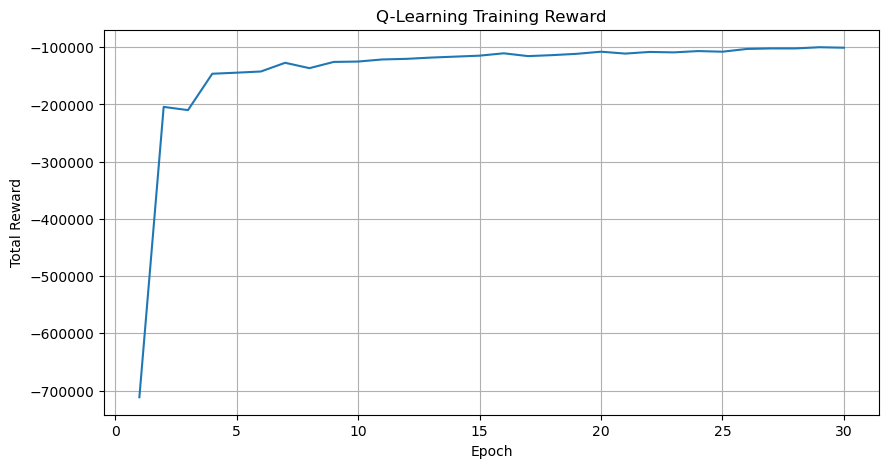

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(range(1, num_epochs + 1), training_rewards)

plt.xlabel("Epoch")
plt.ylabel("Total Reward")
plt.title("Q-Learning Training Reward")
plt.grid(True)
plt.show()

In [20]:
test_df = gongneung_df[
    gongneung_df["STND_DT"] == 20261117
]

test_traffic = test_df.pivot(
    index="STND_TM",
    columns="DIR_NM",
    values="STURN_VOL"
).sort_index()

print("테스트 데이터 크기:", test_traffic.shape)

테스트 데이터 크기: (288, 4)


In [21]:
# 테스트용 차량 유입 생성 (하루에 한 번)
test_arrivals = make_daily_arrivals(
    test_traffic, seed=42
)

for direction in ["동", "서", "남", "북"]:

    original = int(test_traffic[direction].sum())
    generated = sum(test_arrivals[direction])

    print(direction, original, generated)

# 테스트 환경 초기화 (Q-table은 유지!)
waiting_cars = {"동": 0, "서": 0, "남": 0, "북": 0}
signal = 0

test_rewards = []
test_waiting = []
test_actions = []

for minute in range(1440):

    second = minute * 60

    # 현재 State
    state = get_state(second, waiting_cars, signal)

    # 학습된 Q-table에서 Action 선택 (탐험 없음)
    action = choose_action(state, epsilon=0)

    # 신호 변경 여부
    signal_changed = (action != signal)

    # 선택한 신호로 1분간 시뮬레이션
    waiting_cars = simulate_one_minute(
        second, waiting_cars, action,
        previous_signal=signal,
        arrivals=test_arrivals
    )

    # Reward 계산
    reward = calculate_reward(waiting_cars, signal_changed)

    # 결과 기록
    test_rewards.append(reward)
    test_waiting.append(sum(waiting_cars.values()))
    test_actions.append(action)

    # 다음 분을 위한 현재 신호 갱신
    signal = action
    

# 총 대기 차량 수 합계 (분 단위 관측)
total_waiting = sum(test_waiting)
 
# 최대 대기 차량 수
max_waiting = max(test_waiting)

# 평균 대기 차량 수
avg_waiting = np.mean(test_waiting)

# 신호 변경 횟수
signal_changes = sum(
    test_actions[i] != test_actions[i-1]
    for i in range(1, len(test_actions))
)

print("===== Q-learning 테스트 결과 =====")
print("누적 Reward:", sum(test_rewards))
print("평균 대기 차량 수:", avg_waiting)
print("최대 대기 차량 수:", max_waiting)
print("대기 차량 수 합계:", total_waiting)
print("신호 변경 횟수:", signal_changes)
print("Q-Learning 하루 종료 대기 차량 수:",
      sum(waiting_cars.values()))

동 3124 3124
서 3198 3198
남 12417 12417
북 13832 13832
===== Q-learning 테스트 결과 =====
누적 Reward: -19544.19999999979
평균 대기 차량 수: 13.511111111111111
최대 대기 차량 수: 79
대기 차량 수 합계: 19456
신호 변경 횟수: 881
Q-Learning 하루 종료 대기 차량 수: 1


In [22]:
# 각 방향의 초록불 선택 횟수 확인
north_south = test_actions.count(0)
east_west = test_actions.count(1)

print("남북 초록불:", north_south, "분")
print("동서 초록불:", east_west, "분")

print("남북 초록불 비율:", round(north_south / 1440 * 100, 2), "%")
print("동서 초록불 비율:", round(east_west / 1440 * 100, 2), "%")

남북 초록불: 982 분
동서 초록불: 458 분
남북 초록불 비율: 68.19 %
동서 초록불 비율: 31.81 %


In [23]:
# 고정 신호등 테스트
fixed_waiting_cars = {"동": 0, "서": 0, "남": 0, "북": 0}

fixed_rewards = []
fixed_waiting = []
fixed_actions = []

previous_signal = 0

for minute in range(1440):

    second = minute * 60

    # 남북 4분, 동서 1분 고정 신호
    action = 0 if (minute % 5) < 4 else 1

    # 신호 변경 여부
    signal_changed = (action != previous_signal)

    # 1분간 차량 이동
    fixed_waiting_cars = simulate_one_minute(
        second, fixed_waiting_cars, action,
        previous_signal=previous_signal,
        arrivals=test_arrivals
    )

    # Reward 계산
    reward = calculate_reward(
        fixed_waiting_cars, signal_changed
    )

    fixed_rewards.append(reward)
    fixed_waiting.append(sum(fixed_waiting_cars.values()))
    fixed_actions.append(action)

    previous_signal = action

fixed_changes = sum(
    fixed_actions[i] != fixed_actions[i - 1]
    for i in range(1, len(fixed_actions))
)

print("===== 남북 4분 / 동서 1분 고정 신호 결과 =====")

print("누적 Reward:", sum(fixed_rewards))

print("평균 대기 차량 수:", np.mean(fixed_waiting))

print("최대 대기 차량 수:", max(fixed_waiting))

print("대기 차량 수 합계:", sum(fixed_waiting))

print("신호 변경 횟수:", fixed_changes)

print("고정 신호 하루 종료 대기 차량 수:",
      sum(fixed_waiting_cars.values()))

===== 남북 4분 / 동서 1분 고정 신호 결과 =====
누적 Reward: -19943.499999999898
평균 대기 차량 수: 13.809722222222222
최대 대기 차량 수: 49
대기 차량 수 합계: 19886
신호 변경 횟수: 575
고정 신호 하루 종료 대기 차량 수: 9


In [24]:
# ===== 실험 B: 동서 교통량 증가 =====

# 기존 테스트 데이터 복사
congestion_traffic = test_traffic.copy()

# STND_TM이 800, 805 등 HHMM 형식이라고 가정
hours = congestion_traffic.index.astype(int) // 100

# 오전 8시 이상, 10시 미만
mask = (hours >= 8) & (hours < 10)

# 해당 시간대의 동서 차량 수 2배
congestion_traffic.loc[mask, ["동", "서"]] *= 2

print("===== 교통량 변화 확인 =====")
print("기존 동서 교통량:",
      int(test_traffic[["동", "서"]].sum().sum()))

print("변경 후 동서 교통량:",
      int(congestion_traffic[["동", "서"]].sum().sum()))

print("변경된 5분 구간 수:", mask.sum())


===== 교통량 변화 확인 =====
기존 동서 교통량: 6322
변경 후 동서 교통량: 7118
변경된 5분 구간 수: 24


In [25]:
# ===== 실험 B: Q-Learning vs 4:1 고정 신호 =====

# 동일한 교통량, 동일한 차량 유입
congestion_arrivals = make_daily_arrivals(
    congestion_traffic, seed=42
)

results_B = {}

for model in ["Q-Learning", "고정 신호 4:1"]:

    cars = {"동": 0, "서": 0, "남": 0, "북": 0}
    signal = 0

    rewards = []
    waiting = []
    actions = []

    for minute in range(1440):

        second = minute * 60

        # 모델별 행동 선택
        if model == "Q-Learning":
            state = get_state(second, cars, signal)
            action = choose_action(state, epsilon=0.0)

        else:
            # 남북 4분, 동서 1분
            action = 0 if (minute % 5) < 4 else 1

        signal_changed = (action != signal)

        # 동일한 교통 환경에서 시뮬레이션
        cars = simulate_one_minute(
            second, cars, action,
            previous_signal=signal,
            arrivals=congestion_arrivals
        )

        reward = calculate_reward(
            cars, signal_changed
        )

        rewards.append(reward)
        waiting.append(sum(cars.values()))
        actions.append(action)

        signal = action

    changes = sum(
        actions[i] != actions[i-1]
        for i in range(1, len(actions))
    )

    results_B[model] = {
        "누적 Reward": sum(rewards),
        "평균 대기 차량 수": np.mean(waiting),
        "최대 대기 차량 수": max(waiting),
        "신호 변경 횟수": changes,
        "하루 종료 대기 차량 수": sum(cars.values())
    }

print("===== 실험 B 결과 =====")
display(pd.DataFrame(results_B).T.round(2))

===== 실험 B 결과 =====


,누적 Reward,평균 대기 차량 수,최대 대기 차량 수,신호 변경 횟수,하루 종료 대기 차량 수
Q-Learning,-23875.4,16.52,149.0,883.0,1.0
고정 신호 4:1,-53662.5,37.23,339.0,575.0,9.0
